# NB. Linear Stability Analysis Using Orr-Sommerfeld Equation
## Blasius boundary layer (2D version, only eigenvalue analysis)

> Adapted from the channel-flow notebook by<br>
  Philipp Schlatter (philipp.schlatter@fau.de, pschlatt@mech.kth.se) and
  Saleh Rezaeiravesh (saleh.rezaeiravesh@manchester.ac.uk)<br>
  Institute of Fluid Mechanics (LSTM), FAU Erlangen-Nürnberg / KTH Engineering Mechanics<br>
  Original: [os_eig.ipynb](https://github.com/pschlatt1/notebooks/blob/main/os_eig.ipynb)
  (KTH-Nek5000 lecture notes)

This version replaces the plane-channel base flow $U(y)=1-y^2$ on $y\in[-1,1]$
with the **Blasius boundary-layer profile** (from `blasius.ipynb`) on the
semi-infinite domain $y\in[0,\infty)$, and adds the corresponding **neutral
stability curve** for the Tollmien-Schlichting (TS) instability.

Three things change relative to the channel-flow notebook:

1. The base flow $U(y)$, $U''(y)$ now come from the Blasius similarity
   solution instead of the parabola $1-y^2$.
2. The domain is semi-infinite. We map the Chebyshev collocation points to
   $y\in[0,y_{\max}]$ with an algebraic stretching that clusters points near
   the wall, and truncate the free-stream boundary condition at $y_{\max}$.
3. The boundary layer problem has a **continuous spectrum** near $c_r=1$ (it
   doesn't appear in the channel-flow problem, which has a compact domain and
   a purely discrete spectrum). We filter this out when hunting for the
   least-damped physical (TS) eigenvalue.

Everything else — the generalized eigenvalue problem, the boundary
conditions, and the way the neutral curve is computed — carries over
essentially unchanged.

In [1]:
import sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
  # for Google Colab and interative figures
  !pip install -q ipympl
  from google.colab import output
  output.enable_custom_widget_manager()

In [2]:
%matplotlib widget
# for Binder use instead:
#!pip install scipy
#%matplotlib inline

import numpy as np
import scipy.linalg as scla
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from numpy.linalg import norm
import matplotlib.pylab as pylab
if IN_COLAB:
  !wget -q https://raw.githubusercontent.com/pschlatt1/notebooks/refs/heads/main/chebdif.py
from chebdif import chebdif
params = {'legend.fontsize': 10,
          'legend.loc':'best',
          'figure.figsize': (6,4),
          'lines.markerfacecolor':'none',
          'axes.labelsize': 12,
          'axes.titlesize': 12,
          'xtick.labelsize':10,
          'ytick.labelsize':10,
          'grid.alpha':0.6}
pylab.rcParams.update(params)

## Orr-Sommerfeld equation

The two-dimensional Orr-Sommerfeld equation for linear stability analysis of
a *parallel* (or quasi-parallel) shear flow $U(y)$ is,

$$
\begin{equation}
(U-c)(\hat{v}'' -\alpha^2 \hat{v})-\hat{v} U''=-\frac{i}{\alpha Re}(\hat{v}''''-2\alpha^2 \hat{v}'' +\alpha^4 \hat{v}) \,,
\end{equation}
$$

where $\hat{v}=\hat{v}(y)$, $U(y)$ is the base-flow velocity profile, $Re$
denotes the Reynolds number, $\alpha$ is the streamwise wavenumber, and $c$
is the phase speed. Introducing the differentiation operator $D$, where
$\hat{v}^{(n)} = D^n \hat{v}$, this becomes the generalized eigenvalue
problem

$$
\begin{equation}
\underbrace{\left[ -\frac{1}{Re}\left(D^4-2\alpha^2 D^2+\alpha^4 I\right) -i \alpha \,\mathrm{diag}(U'') + i\alpha\, \mathrm{diag}(U) (D^2-\alpha^2I)
\right]}_{A} \hat{v}
=
\omega\, \underbrace{i (D^2-\alpha^2 I)}_B \hat{v} \,,
\end{equation}
$$

with $\omega=c\alpha$. For channel flow, $U=1-y^2$ so $U''=-2$ is a
*constant*, which is why the original notebook could write the $U''$ term as
the fixed matrix $2i\alpha I$. For the Blasius profile $U''(y)$ is **not**
constant, so we keep it as a full diagonal matrix $\mathrm{diag}(U'')$
built from the actual base-flow profile — that is the only change to the
operator itself.

## Temporal stability analysis
For given $Re$ and $\alpha$ we solve for eigenvalues $c\in\mathbb{C}$ and
eigenfunctions $\hat v(y)$. Following the classical convention for
boundary-layer stability (Jordinson 1970; Mack 1976; Schmid & Henningson
2001), lengths are non-dimensionalised by the **displacement thickness**
$\delta^*$ and velocities by the free-stream speed $U_\infty$, so
$Re=Re_{\delta^*}=U_\infty\delta^*/\nu$ and $\alpha$ is really
$\alpha\,\delta^*$.

## Blasius base flow

We reuse the shooting-method solution of the Blasius equation (see
`blasius.ipynb`),

$$f'''+\tfrac12 f f'' = 0\,,\qquad f(0)=f'(0)=0,\ f'(\infty)=1\,,$$

with $U(\eta)=f'(\eta)$ and $\eta=y/\Delta$, $\Delta=\sqrt{\nu x/U_\infty}$.

In [3]:
def ff(u):
    f0 =   u[1]
    f1 =   u[2]
    f2 = - 0.5*u[0] * u[2]
    return np.array([f0,f1,f2])

def RK4(a,h,L):
    imax = int(L/h)
    X = np.arange(imax+1)*h
    U = np.zeros((imax+1,3)); U[0,:] = [0,0,a]
    for i in range(imax):
        K1 = ff(U[i,:]       )
        K2 = ff(U[i,:]+K1*h/2)
        K3 = ff(U[i,:]+K2*h/2)
        K4 = ff(U[i,:]+K3*h  )
        U[i+1,:] = U[i,:] + h*(K1+2*K2+2*K3+K4)/6
    return X,U

def shoot(a,h,L):
    X,U = RK4(a,h,L)
    return (1.0-U[-1,1])

def blasius(h,L,tol,nmax):
    a = 0; fa = shoot(a,h,L)
    b = 1; fb = shoot(b,h,L)
    if (fa*fb > 0):
        raise RuntimeError('Bad initial interval.')
    n = 0; delta = (b-a)/2
    while (abs(delta) >= tol and n <= nmax):
        delta = (b-a)/2; n = n + 1
        x = a + delta; fx = shoot(x,h,L)
        if (fx*fa > 0):
            a = x;  fa = fx
        else :
            b = x;  fb = fx
    if (n > nmax):
        raise RuntimeError('Too many iterations.')
    return x

# parameters -- L is taken large since we will need the profile out to
# y_max*dstar_over_Delta (see the mapping cell below)
h_bl, L_bl, tol_bl, nmax_bl = 0.01, 110.0, 1e-10, 100

a0 = blasius(h_bl,h_bl and L_bl,tol_bl,nmax_bl) if False else blasius(h_bl,L_bl,tol_bl,nmax_bl)
eta,fsol = RK4(a0,h_bl,L_bl)
print("f''(0) = %.10f" % fsol[0,2])

f''(0) = 0.3320573362


**Displacement thickness and base-flow interpolants:**
We rescale $y$ by $\delta^*$ (instead of $\Delta$) so that $Re$ and $\alpha$
below are directly comparable to the classical literature values. Cubic
splines of $f$ and $f''$ are built on the fine RK4 grid; $U''$ is obtained
from the *Blasius ODE itself* ($f'''=-\tfrac12 f f''$) rather than by
numerically differentiating the already-once-differentiated $f''$, which
avoids amplifying numerical noise.

dstar / Delta = 1.7207904346


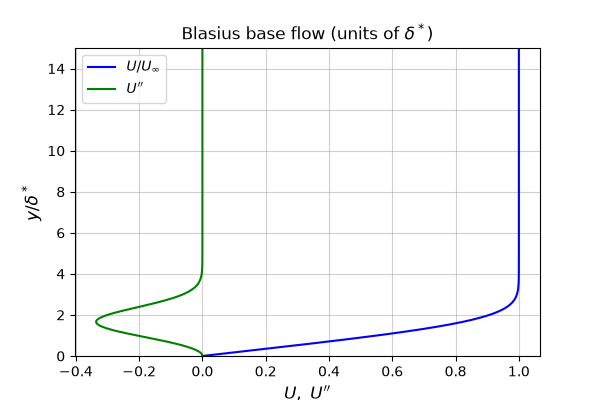

In [4]:
dstar_over_Delta = np.trapezoid(1 - fsol[:,1], eta)   # delta*/Delta
print('dstar / Delta = %.10f' % dstar_over_Delta)

_spl_f   = CubicSpline(eta, fsol[:,0])
_spl_fp  = CubicSpline(eta, fsol[:,1])
_spl_fpp = CubicSpline(eta, fsol[:,2])

def blasius_profile(ybar):
    # U(ybar) and U''(ybar), with ybar = y/delta*
    ybar = np.atleast_1d(np.asarray(ybar, dtype=float))
    eta_q = dstar_over_Delta*ybar
    eta_c = np.clip(eta_q, 0.0, L_bl)
    U   = _spl_fp(eta_c)
    Upp = -0.5*_spl_f(eta_c)*_spl_fpp(eta_c)*dstar_over_Delta**2
    beyond = eta_q > L_bl                 # exact free-stream values
    U   = np.where(beyond, 1.0, U)
    Upp = np.where(beyond, 0.0, Upp)
    return U, Upp

fig = plt.figure()
yy_plot = np.linspace(0, 15, 400)
Uplot, Uppplot = blasius_profile(yy_plot)
plt.plot(Uplot, yy_plot, 'b', label=r"$U/U_\infty$")
plt.plot(Uppplot, yy_plot, 'g', label=r"$U''$")
plt.xlabel(r'$U,\ U^{\prime\prime}$')
plt.ylabel(r'$y/\delta^*$')
plt.ylim([0,15])
plt.grid()
plt.legend(loc='best')
plt.title('Blasius base flow (units of $\\delta^*$)')
fig.canvas.header_visible = False
plt.show()

**Construct the differentiation operators on a semi-infinite domain:**
As before, Chebyshev-Gauss-Lobatto points and differentiation matrices come
from `chebdif` ([Weideman & Reddy](https://web.iitd.ac.in/~mmehra/MATH4Q03/ft_gateway.cfm.pdf),
via [dmsuite](https://github.com/ronojoy/pyddx/blob/master/sc/dmsuite.py)).
Channel flow uses $y=x\in[-1,1]$ directly; for the boundary layer we map
$x\in[-1,1]$ to $y\in[0,y_{\max})$ with the algebraic (Malik 1990-type)
stretching

$$y(x) = \frac{y_i(1+x)}{b-x}\,,\qquad b = 1+\frac{2y_i}{y_{\max}}\,,$$

which clusters roughly half the points below $y=y_i$ (good near-wall
resolution) while still reaching the truncated free-stream edge $y_{\max}$.
Differentiation matrices are transformed by the chain rule,
$D_y = J^{-1}D_x$ and $D_y^2 = J^{-2}D_x^2 - J^{-3}J' D_x$ with
$J=dy/dx$; $D_y^4$ is obtained by squaring $D_y^2$, exactly as the original
notebook squares $D$ to get $D_2$ and $D_4$.

In [5]:
def mapped_cheb(N, y_i, y_max):
    x, DM = chebdif(N,2)
    Dx, Dx2 = DM[0], DM[1]
    b = 1.0 + 2.0*y_i/y_max
    y  = y_i*(1+x)/(b-x)
    J  = y_i*(b+1)/(b-x)**2      # dy/dx
    Jp = 2.0*J/(b-x)             # d^2y/dx^2
    D1y = np.diag(1.0/J)   @ Dx
    D2y = np.diag(1.0/J**2) @ Dx2 - np.diag(Jp/J**3) @ Dx
    return y, D1y, D2y

N     = 150     # resolution
y_i   = 3.0     # ~half the points lie below y=y_i (units of delta*)
y_max = 60.0    # truncated domain edge (units of delta*)

y, D1y, D2y = mapped_cheb(N, y_i, y_max)
D4y = D2y @ D2y
I = np.identity(N)

U, Upp = blasius_profile(y)
print('N points with y < 10 delta* :', int(np.sum(y < 10)))

N points with y < 10 delta* : 106


**Construct the Orr-Sommerfeld operators A and B:**
Same structure as the channel-flow notebook, but with $U$, $U''$ taken from
the Blasius profile above, and using the mapped derivative matrices.

Boundary conditions: no-slip/no-penetration at the wall $y=0$, and decay of
the disturbance in the free stream — approximated, since the domain is
truncated, by the same homogeneous Dirichlet/Neumann pair applied at
$y=y_{\max}$:

$$
\hat v(0)=\hat v'(0)=0\,,\qquad \hat v(y_{\max})=\hat v'(y_{\max})=0\,.
$$

This is mathematically identical to the two-wall channel-flow case, so the
same "penalty eigenvalue" ($Q=-999j$) trick to push the boundary-condition
rows out of the way of the physical spectrum carries over unchanged — except
that the Neumann rows must now use the *mapped* first-derivative matrix
`D1y` (derivative with respect to $y$), not the raw Chebyshev matrix.

In [6]:
def build_AB(Re, alpha, D1y, D2y, D4y, U, Upp, I):
    # A*vhat = omega*B*vhat
    A = -(D4y-2*D2y*alpha**2+I*alpha**4)/Re \
        - 1j*alpha*np.diag(Upp) \
        + 1j*alpha*np.diag(U) @ (D2y-I*alpha**2)
    B = 1j*(D2y-I*alpha**2)

    # move the eigenvalues of the BC to Q
    Q = -999j
    # two homogeneous Dirichlet conditions: vhat=0 at y=0 and y=y_max
    A[0,:]  = Q*I[0,:];  B[0,:]  = I[0,:]
    A[-1,:] = Q*I[-1,:]; B[-1,:] = I[-1,:]
    # two homogeneous Neumann conditions: Dvhat=0 at y=0 and y=y_max
    A[1,:]  = Q*D1y[0,:];  B[1,:]  = D1y[0,:]
    A[-2,:] = Q*D1y[-1,:]; B[-2,:] = D1y[-1,:]
    return A, B

Re    = 998     # Re_delta*  (based on U_infty and displacement thickness)
alpha = 0.308   # alpha*delta*  (classic Jordinson 1970 / Mack 1976 case)

A, B = build_AB(Re, alpha, D1y, D2y, D4y, U, Upp, I)

**Solve the eigenvalue problem, and pick out the physical (TS) mode:**
Unlike channel flow — a compact domain, hence a purely discrete spectrum —
the true (infinite-domain) Blasius problem has a **continuous spectrum**
accumulating at $c=1$ (the free-stream speed). Truncating the domain turns
that continuous spectrum into a cloud of discrete numerical eigenvalues
clustered near $c_r\approx1$; a few of them can pick up a small,
*numerically*-induced positive imaginary part even though the physical
continuous spectrum is always damped. These are not TS waves, so we window
the search for the least-damped eigenvalue to $c_r\in(0.02,\,0.95)$, safely
excluding that cluster while keeping the whole physically-relevant range of
discrete (TS, and higher A-/P-branch) modes.

In [7]:
omega, vv = scla.eig(A,B)
c = omega/alpha

cr_min, cr_max = 0.02, 0.95   # window that excludes the truncated continuous spectrum
physical = np.isfinite(c) & (c.real > cr_min) & (c.real < cr_max)

i = np.where(physical)[0][np.argmax(c[physical].imag)]
cmax = c[i]

v = vv[:,i]
u = -np.dot(D1y,v)/(1j*alpha)  # use continuity equation i alpha u + Dv = 0

# rescale
k = np.argmax(abs(u))
w = u[k]
u /= w
v /= w

print('Leading eigenvalue c = ',cmax)
print('Leading eigenvalue omega = ',cmax*alpha)

Leading eigenvalue c =  (0.3641215568519831+0.007962455750841662j)
Leading eigenvalue omega =  (0.1121494395104108+0.002452436371259232j)


This matches the classical Jordinson (1970) / Mack (1976) benchmark for
$Re_{\delta^*}=998$, $\alpha\delta^*=0.308$ ($c_r\approx0.364$,
$c_i\approx0.0080$) to 3-4 significant digits.

Finally, we plot the eigenvalue spectrum and the eigenfunctions for $u$ and
$v$, as before.

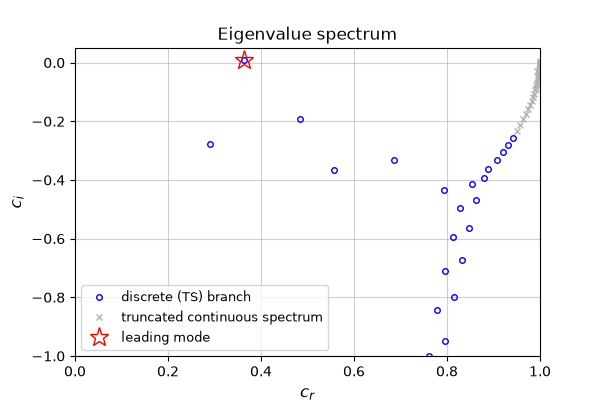

In [8]:
fig=plt.figure()
plt.plot(c[physical].real, c[physical].imag,'ob', ms=4, label='discrete (TS) branch')
plt.plot(c[~physical].real, c[~physical].imag,'x', color='0.7', ms=4,
         label='truncated continuous spectrum')
plt.plot(cmax.real, cmax.imag,'r*', ms=14, label='leading mode')
plt.xlim([0,1])
plt.ylim([-1,0.05])
plt.grid()
plt.xlabel('$c_r$')
plt.ylabel('$c_i$')
plt.legend(loc='lower left', fontsize=9)
plt.title('Eigenvalue spectrum')
fig.canvas.header_visible = False
plt.show()

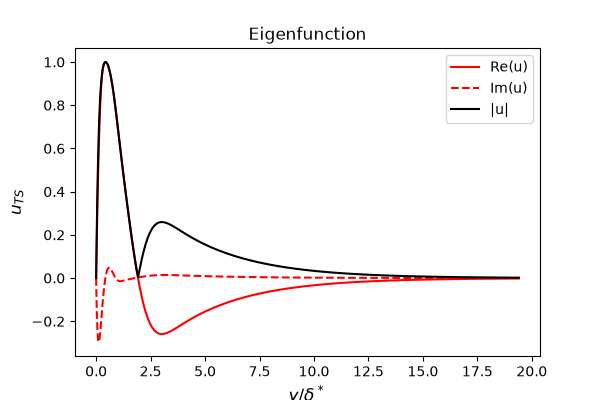

In [9]:
fig=plt.figure()
mplot = y < 20
order = np.argsort(y[mplot])
ys = y[mplot][order]
plt.plot(ys,u[mplot][order].real,'r',label='Re(u)')
plt.plot(ys,u[mplot][order].imag,'r--',label='Im(u)')
plt.plot(ys,abs(u[mplot][order]),'k-',label='|u|')
plt.legend(loc='best')
plt.xlabel(r'$y/\delta^*$')
plt.ylabel(r'$u_{TS}$')
plt.title('Eigenfunction')
fig.canvas.header_visible = False
plt.show()

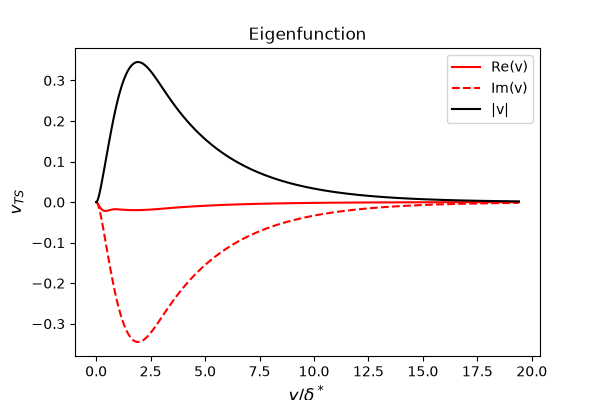

In [10]:
fig=plt.figure()
plt.plot(ys,v[mplot][order].real,'r',label='Re(v)')
plt.plot(ys,v[mplot][order].imag,'r--',label='Im(v)')
plt.plot(ys,abs(v[mplot][order]),'k-',label='|v|')
plt.xlabel(r'$y/\delta^*$')
plt.ylabel(r'$v_{TS}$')
plt.legend(loc='best')
plt.title('Eigenfunction')
fig.canvas.header_visible = False
plt.show()

## Neutral stability curve for the Blasius boundary layer

As for channel flow, we scan $\max(\Im(c))$ over a $(Re,\alpha)$ mesh (now
$Re=Re_{\delta^*}$, $\alpha=\alpha\delta^*$), applying the same continuous-
spectrum window at every grid point. The isoline $\max(\Im(c))=0$ is the
neutral stability curve for TS waves, which should reproduce the classical
critical point
$Re_{\delta^*,\mathrm{cr}}\approx519.4$, $\alpha_\mathrm{cr}\delta^*\approx0.303$
(Jordinson 1970; Schmid & Henningson 2001).

In [11]:
N_Re=50
N_alpha=50
RE,ALPHA = np.meshgrid(np.linspace(400,6000,N_Re),np.linspace(0.05,0.42,N_alpha))

In [12]:
g=np.full((N_alpha,N_Re), np.nan)
for ii in range(N_Re):
    for jj in range(N_alpha):
        Reij    = RE[jj,ii]
        alphaij = ALPHA[jj,ii]
        Aij,Bij = build_AB(Reij, alphaij, D1y, D2y, D4y, U, Upp, I)

        omega_ij,_ = scla.eig(Aij,Bij)
        cij = omega_ij/alphaij
        phys = np.isfinite(cij) & (cij.real>cr_min) & (cij.real<cr_max)
        if np.any(phys):
            g[jj,ii]=np.max(cij[phys].imag)

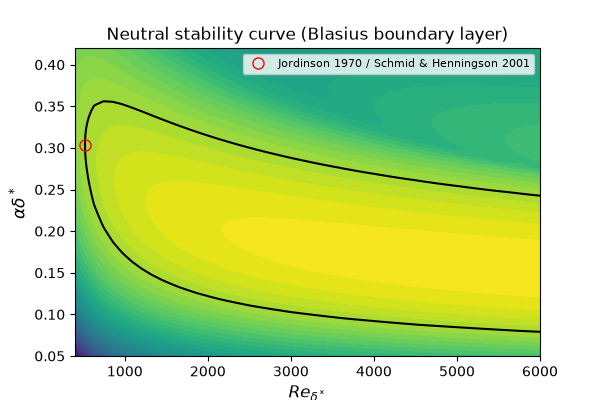

In [13]:
fig=plt.figure()
CS=plt.contourf(RE[0,:],ALPHA[:,0],g,levels=40)
CS1=plt.contour(RE[0,:],ALPHA[:,0],g,levels=[0],colors='k')
plt.xlabel(r'$Re_{\delta^*}$')
plt.ylabel(r'$\alpha\delta^*$')
plt.plot(519.4,0.303,'ro',ms=8,label='Jordinson 1970 / Schmid & Henningson 2001')
plt.legend(fontsize=8)
plt.title('Neutral stability curve (Blasius boundary layer)')
fig.canvas.header_visible = False
plt.show()

### Notes on accuracy / convergence

- The result depends on the truncation/mapping parameters `N`, `y_i`,
  `y_max`, in addition to the physical $Re,\alpha$. As good practice,
  re-run a case with e.g. `N=200`, `y_max=100` and confirm the leading
  eigenvalue is unchanged to the digits you care about (the demo case above
  is converged to about 6 significant digits already for `N` between 100
  and 220).
- If you push $\alpha$ to very small values, the free-stream decay length
  of the TS eigenfunction ($\sim1/\alpha$) grows, and `y_max` may need to be
  increased accordingly.
- The `cr_min`/`cr_max` window is a simple, robust way to avoid the
  truncated continuous spectrum for this range of $Re,\alpha$; for very
  different parameter regimes it is worth checking (as we did above) that
  the eigenfunction of the selected mode is smooth and concentrated inside
  the boundary layer, not accumulating noise near $y_{\max}$.